# Formas de onda gravitacionais no domínio da frequência

Neste notebook, vamos aprender:

- Como representar graficamente um sinal de onda gravitacional.
- Por que a frequência do sinal é menor nos instantes iniciais e aumenta à medida que os objetos compactos se aproximam da fusão.
- Como converter o sinal do domínio do tempo para o domínio da frequência.

In [8]:
# -- Para usar no Google Colab, descomente a linha abaixo para instalar o PyCBC.
!pip install -q pycbc

Text(0.5, 1.0, 'Forma de onda completa')

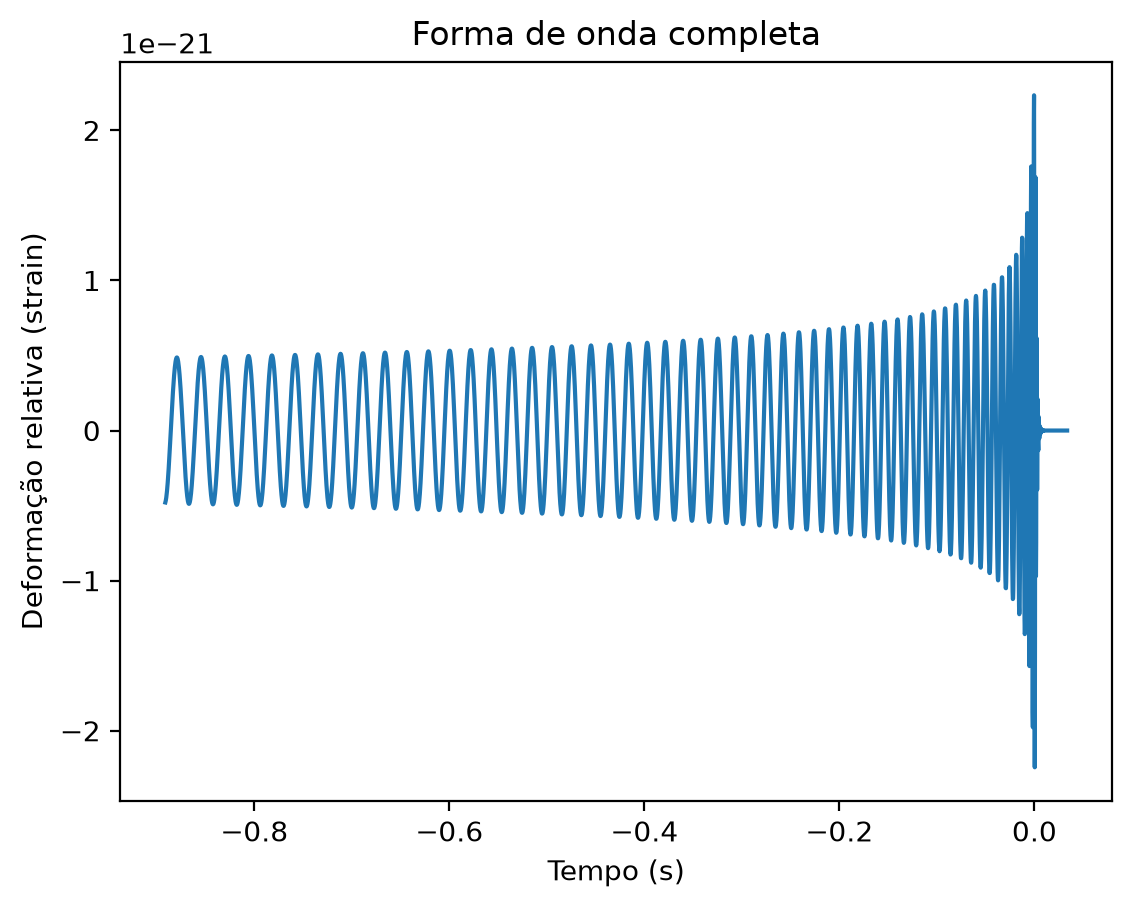

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from pycbc.waveform import get_td_waveform
%matplotlib inline
%config InlineBackend.figure_format='retina'

# -- Definir a frequência de amostragem e o modelo de forma de onda
fs = 4096
apx = 'SEOBNRv2'

# -- Gerar as duas polarizações da onda gravitacional
hp, hc = get_td_waveform(approximant=apx,
                         mass1=10,
                         mass2=10,
                         delta_t=1.0/fs,
                         distance=100,
                         f_lower=40)

# -- Construir o vetor de tempo e representar a polarização h+
time = hp.sample_times
plt.plot(time, hp)
plt.xlabel('Tempo (s)')
plt.ylabel('Deformação relativa (strain)')
plt.title('Forma de onda completa')

## Evolução da frequência

A frequência da forma de onda acima varia com o tempo. Inicialmente, os objetos compactos (buracos negros ou estrelas de nêutrons) estão relativamente distantes um do outro e, portanto, apresentam períodos orbitais mais longos. Esses períodos orbitais produzem sinais de frequências mais baixas.

À medida que os objetos compactos se aproximam, seus movimentos orbitais ficam mais rápidos, produzindo sinais de frequências cada vez maiores.

Vamos observar esse comportamento com mais detalhes.

#### Trecho inicial do sinal

Vamos representar apenas a parte inicial da forma de onda.

**1.** Observe o gráfico abaixo e conte a quantidade de oscilações por unidade de tempo para estimar a frequência do sinal nesse trecho, ainda distante da fusão.

*Dica: a frequência é medida em ciclos por segundo.*

Text(0, 0.5, 'Deformação relativa (strain)')

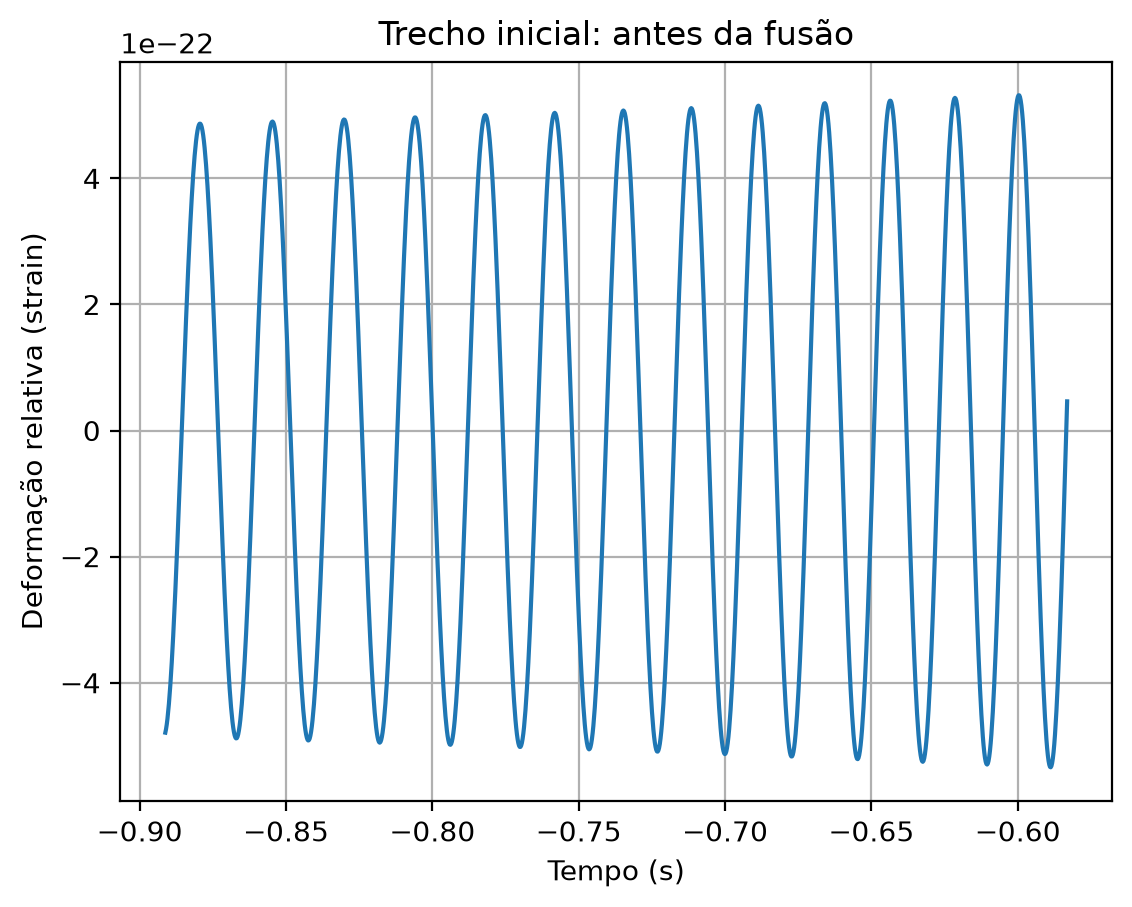

In [11]:
n = len(hp)
indx = slice(0, int(n/3))
plt.plot(time[indx], hp[indx])
plt.grid()
plt.title('Trecho inicial: antes da fusão')
plt.xlabel('Tempo (s)')
plt.ylabel('Deformação relativa (strain)')

# -- Conte os picos por unidade de tempo para estimar a frequência
# -- nesse trecho inicial do sinal.
# -- Dica: a frequência é medida em ciclos por segundo.

#### Trecho final do sinal

Vamos representar apenas a parte final da forma de onda, próxima ao instante da fusão.

**2.** Observe o gráfico abaixo e conte a quantidade de oscilações por unidade de tempo para estimar a frequência nesse trecho. Considere o intervalo de \(-0{,}02\) s até a fusão, em \(t=0\).

Text(0.5, 1.0, 'Trecho final: próximo à fusão')

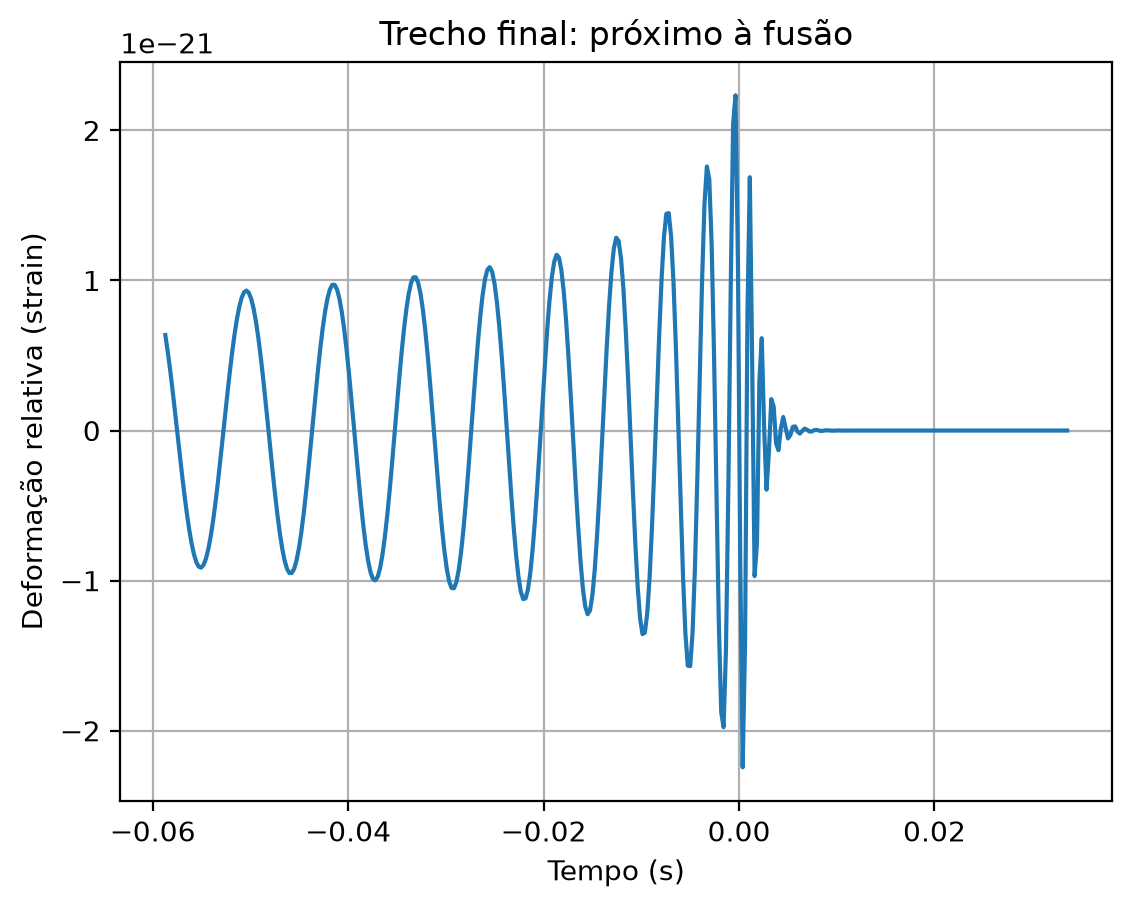

In [12]:
# -- Representar o trecho final, próximo à fusão
indx = slice(int(9*n/10), None)
plt.figure()
plt.plot(time[indx], hp[indx])
plt.grid()
plt.xlabel('Tempo (s)')
plt.ylabel('Deformação relativa (strain)')
plt.title('Trecho final: próximo à fusão')

In [11]:
# -- Exemplo opcional com transformada Q (mantido comentado)
# help(hp.qtransform)
# noise = np.random.normal(len(hp))*1e-23
# w_noise = hp + noise
# t, f, qplane = w_noise.qtransform()

## Sinal no domínio da frequência

Podemos representar o mesmo sinal no domínio da frequência. Esperamos encontrar uma magnitude espectral maior nas frequências mais baixas, pois a forma de onda permanece por mais tempo nessas frequências. Nas frequências mais elevadas, a magnitude tende a ser menor, correspondendo aos instantes imediatamente anteriores à fusão. Acima da frequência característica da fusão, a magnitude diminui rapidamente, pois o movimento orbital dos objetos compactos não continua acelerando indefinidamente.

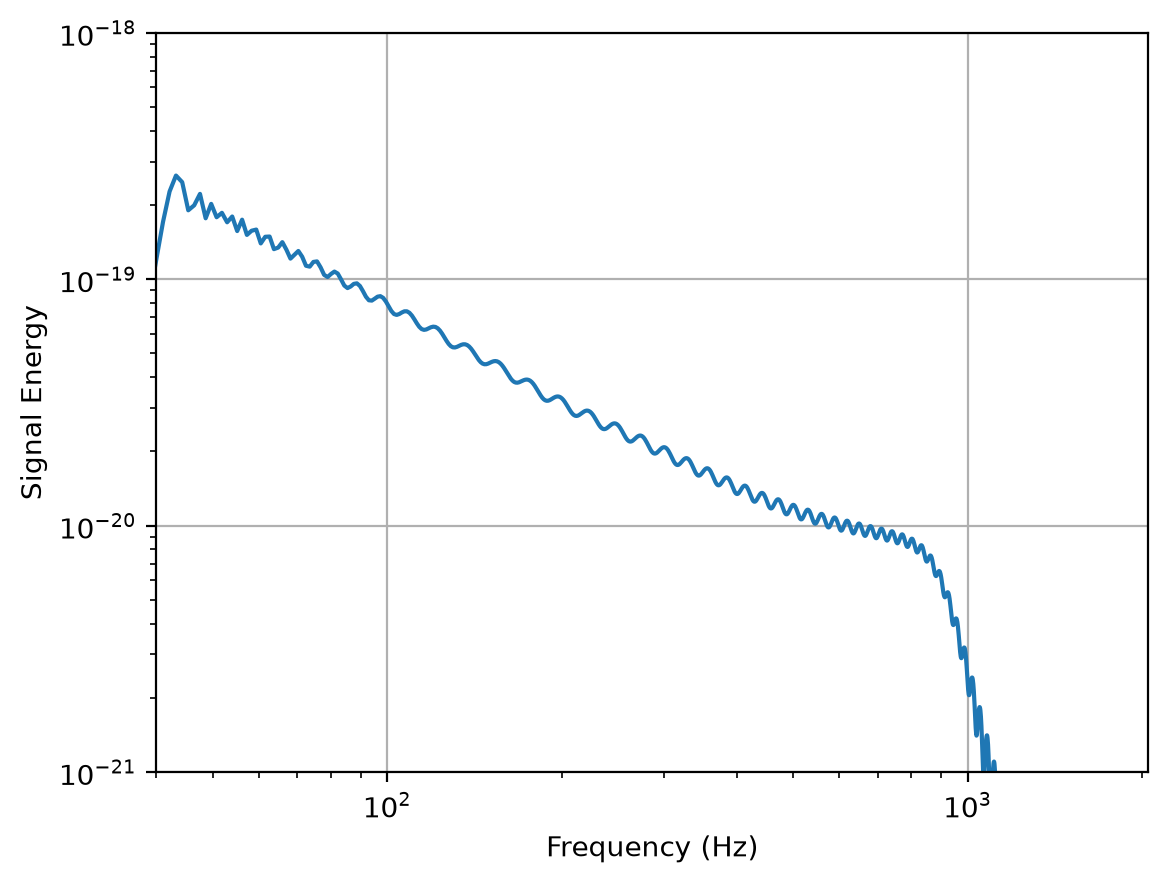

In [14]:
# -- Plot in the frequency domain
from scipy import signal
win = signal.windows.tukey(len(hp))
hp_win = win*hp
hp_freq = np.fft.rfft(hp)
frequencies = np.fft.rfftfreq(len(hp))*fs

plt.loglog(frequencies, np.abs(hp_freq))
plt.xlim(40,fs/2)
plt.ylim(1e-21, 1e-18)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Signal Energy')
plt.grid()

## Questões de verificação

1. No trecho inicial do sinal, qual foi a frequência que você estimou?
2. No trecho final, próximo à fusão, qual foi a frequência que você estimou?
3. Qual é a duração total, em segundos, da forma de onda deste exemplo?
4. No espectro no domínio da frequência, em qual frequência a magnitude do sinal é maior? Você consegue explicar por quê?

## Pratique com Python

1. Gere uma forma de onda semelhante à utilizada neste notebook, mas com `mass1 = mass2 = 20` massas solares.
2. Represente no mesmo gráfico os espectros no domínio da frequência dessa nova forma de onda (sistema de maior massa) e da forma de onda original (sistema de menor massa).
3. Qual dos dois sistemas apresenta maior frequência de fusão?
4. Qual dos dois sistemas apresenta maior magnitude espectral na frequência de 100 Hz?